<div style="padding:20px;color:white;font-size:240%;text-align:center;border-radius:5px;background-color:#023c66;font-weight:700;border:5px solid #F28C28;">Module 4 — Worksheet 3: Model Performance for Propensity Models</div>

**Course:** ISA 591 — Introduction to Data Mining in Business  
**Module 4:** Evaluating Model Performance  
**Focus:** Predicted probabilities, thresholds, ROC/AUC, ranking, lift, gains, and targeting decisions

## Learning Goals

1. Explain the difference between a predicted class and a propensity score.
2. Convert probabilities into classes using a threshold.
3. Explain the recall/specificity tradeoff when thresholds change.
4. Construct and interpret an ROC curve and AUC.
5. Use propensity scores to rank customers.
6. Calculate lift for a targeted group.
7. Interpret cumulative gains/lift in a business targeting problem.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns',100)
print('Ready!')

Ready!


## Roadmap

A classification model can produce more than a 0/1 decision.

**Model → predicted probability (propensity) → threshold OR ranking → business action**

Propensity models are especially useful when a business wants to **rank** cases rather than classify everyone using one fixed cutoff.

---
# 1. Predicted Classes vs. Propensities

For logistic regression:

```python
model.predict(X)
```

returns predicted classes.

```python
model.predict_proba(X)[:,1]
```

returns estimated probabilities for the positive class.

A probability such as 0.72 is a **propensity score**: the model estimates a relatively high likelihood of the positive outcome.

In [ ]:
df=pd.read_csv("https://raw.githubusercontent.com/martinwg/ISA591/refs/heads/main/data/fraud_small_imbalanced.csv")
df.dropna(inplace=True) ## 1 obs (missing y)

## dummy encoding
df = pd.get_dummies(df, drop_first=True, dtype = int)
df.head()

,cc_num,amt,is_fraud,gender_M,category_food_dining,category_gas_transport,category_grocery_net,category_grocery_pos,category_health_fitness,category_home,category_kids_pets,category_misc_net,category_misc_pos,category_personal_care,category_shopping_net,category_shopping_pos,category_travel
0,2.291160e+15,2.86,0.0,1,0,0,0,0,0,0,0,0,0,1,0,0,0
1,3.573030e+15,29.84,0.0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
2,3.598220e+15,41.28,0.0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
3,3.591920e+15,60.05,0.0,1,0,0,0,0,0,0,0,0,1,0,0,0,0
4,3.526830e+15,3.19,0.0,1,0,0,0,0,0,0,0,0,0,0,0,0,1


In [ ]:
## imbalance (severe)
df['is_fraud'].value_counts()

is_fraud
0.0    129620
1.0       526
Name: count, dtype: int64

In [ ]:
## split X and y
X=df.drop(columns="is_fraud")
y=df["is_fraud"].astype(int)

## Logistic model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

## split TRAIN / TEST
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=591,stratify=y)

## fit
lr=LogisticRegression(max_iter=1000)
lr.fit(X_train,y_train)

## propensities and predictions
# Propensity for class 1
p_hat=lr.predict_proba(X_test)[:,1]
y_hat=lr.predict(X_test) 

pd.DataFrame({"Actual":y_test.values,"Propensity":p_hat})

,Actual,Propensity
0,0,0.498251
1,0,0.499991
2,0,0.499332
3,0,0.498962
4,0,0.498251
...,...,...
26025,0,0.499948
26026,0,0.499938
26027,0,0.498107
26028,0,0.499901


The accuracy of the model is 0.9959661928543988


0.5

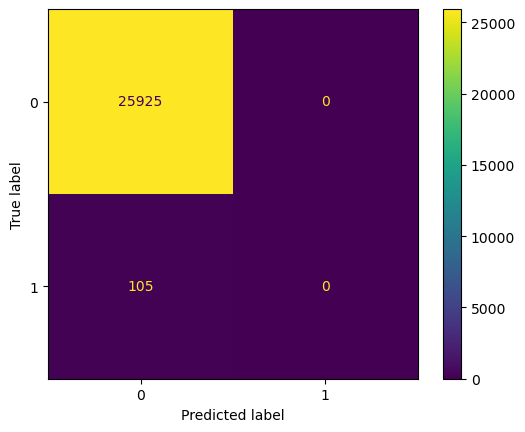

In [8]:
## 0.5 cutoff (PREDICT)
#### performance
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score
ConfusionMatrixDisplay(confusion_matrix(y_test, y_hat)).plot()
print(f"The accuracy of the model is {accuracy_score(y_test, y_hat)}")

## if dataset is imbalanced, use balanced_accuracy_score
balanced_accuracy_score(y_test, y_hat)

In [9]:
## LET'S BALANCE THE DATA
from imblearn.over_sampling import SMOTE

smote = SMOTE()

## CREATE BALANCED DATA
#### ONLY FOR THE TRAINING SET
X_train_B, y_train_B = smote.fit_resample(X_train, y_train)

c:\Users\martinwg\.conda\envs\intro-data-mining\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


In [10]:
y_train_B.value_counts()

is_fraud
0    103695
1    103695
Name: count, dtype: int64

In [11]:
## fit a RF on the BALANCED DATA SET
from sklearn.ensemble import RandomForestClassifier

## instance
rf = RandomForestClassifier(n_jobs = -1)

## fit on the BALANCED data set
rf.fit(X_train_B, y_train_B)

## predictions and propensities on TEST 
y_hat = rf.predict(X_test)
p_hat = rf.predict_proba(X_test)[:,1]

The accuracy of the model is 0.9877449097195543


0.8088855214216835

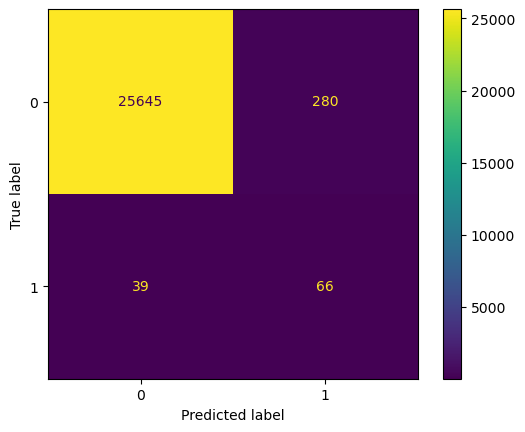

In [12]:
## 0.5 cutoff (PREDICT)
#### performance
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score
ConfusionMatrixDisplay(confusion_matrix(y_test, y_hat)).plot()
print(f"The accuracy of the model is {accuracy_score(y_test, y_hat)}")

## if dataset is imbalanced, use balanced_accuracy_score
balanced_accuracy_score(y_test, y_hat)

## Practice 1A — Rank by propensity

Create a DataFrame containing the actual outcome and propensity, then sort from highest to lowest propensity.

In [13]:
# TODO
ranked=pd.DataFrame({"Actual":y_test.values,"Propensity":p_hat}).sort_values("Propensity",ascending=False)

ranked.head(15)

,Actual,Propensity
9532,1,1.0
41,1,1.0
2741,1,1.0
18900,0,1.0
10280,1,1.0
22799,0,1.0
933,0,1.0
7933,0,1.0
13038,0,1.0
16409,1,1.0


---
# 2. Thresholds Convert Propensities Into Classes

The default classification threshold is commonly 0.50:

$$
\hat y=
\begin{cases}
1 & \hat p > threshold \\
0 & otherwise
\end{cases}
$$

But 0.50 is a decision rule—not a law.

Changing the threshold changes the confusion matrix.

## Practice 2A — Try several thresholds

In [14]:
from sklearn.metrics import confusion_matrix,accuracy_score,recall_score,precision_score

def threshold_metrics(y_true,p,threshold):
    pred=(p>threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_true,pred).ravel()
    return {
        "Threshold":threshold,
        "Accuracy":accuracy_score(y_true,pred),
        "Recall":recall_score(y_true,pred,zero_division=0),
        "Specificity":tn/(tn+fp),
        "FPR": 1-(tn/(tn+fp)),
        "Precision":precision_score(y_true,pred,zero_division=0),
        "Predicted Positives":pred.sum()
    }

# TODO
threshold_results=None

threshold_results=pd.DataFrame([
     threshold_metrics(y_test,p_hat,t)
     for t in [0.7, 0.6, 0.5, 0.4, 0.3]
])

threshold_results

,Threshold,Accuracy,Recall,Specificity,FPR,Precision,Predicted Positives
0,0.7,0.991318,0.533333,0.993173,0.006827,0.240343,233
1,0.6,0.989935,0.590476,0.991553,0.008447,0.220641,281
2,0.5,0.987745,0.628571,0.989200,0.010800,0.190751,346
3,0.4,0.985209,0.685714,0.986422,0.013578,0.169811,424
4,0.3,0.981406,0.723810,0.982449,0.017551,0.143126,531


### Interpretation

As the threshold decreases:

1. What happens to the number predicted positive?
2. What generally happens to recall?
3. What generally happens to specificity?
4. Why is the best threshold a **business decision**, not just a statistical decision?

**Your response:**  
1.  
2.  
3.  
4.

---
# 3. ROC Curve

The ROC curve evaluates the model across **all classification thresholds**.

It plots:

- x-axis: False Positive Rate = $1-Specificity$
- y-axis: True Positive Rate = Recall

A useful model should generally move toward the upper-left portion of the plot.

In [15]:
### 1) get the ROC curve to determine if the model is good overall
##### AUC (area under the curve) - closer to 1 the better, closer to 0.5 the worse
from sklearn.metrics import roc_curve,auc

# TODO

fpr,tpr,thresholds=roc_curve(y_test,p_hat)
auc_value=auc(fpr,tpr)

print("AUC:",auc_value)

AUC: 0.9664780272764845


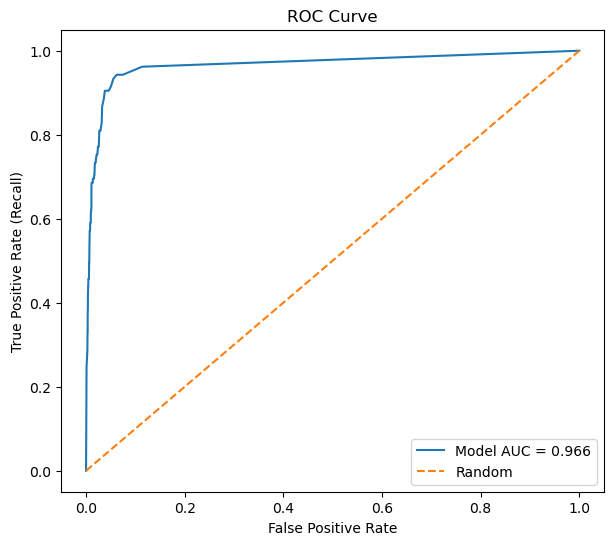

In [16]:
# TODO
plt.figure(figsize=(7,6))
plt.plot(fpr,tpr,label=f"Model AUC = {auc_value:.3f}")
plt.plot([0,1],[0,1],linestyle="--",label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend()
plt.show()

---
# 4. AUC

AUC summarizes the ROC curve.

A useful interpretation is:

> If we randomly choose one positive case and one negative case, AUC is the probability that the model gives the positive case a higher propensity.

- AUC = 0.50 → no ranking ability beyond random
- AUC = 1.00 → perfect ranking

AUC measures **ranking/discrimination**, not whether predicted probabilities are perfectly calibrated.

## Practice 4A — Threshold from ROC

A common statistical criterion is to maximize:

$$TPR-FPR$$

This is related to Youden's $J$ statistic.

Calculate that threshold—but remember that a business may prefer a different threshold when costs differ.

In [17]:
# TODO
#### What if you dont know which threshold to choose
#### MAXIMIZE TPR - FPR
#### Does NOT take into account that some problems are more expensive than others 

j=tpr-fpr
optimal_threshold=thresholds[np.argmax(j)]

print("ROC-based threshold:",optimal_threshold)

ROC-based threshold: 0.03


In [18]:
(2/4) / (4/14)

1.75

---
# 5. Propensity Modeling as Ranking

Sometimes the business does not need a threshold at all.

Example:

> A marketing team can contact only 1,000 customers. Rank customers by propensity and contact the top 1,000.

This turns the model into a **ranking model**.

## Practice 5A — Top 10% targeting

Select the top 10% of test observations based on propensity.

In [19]:
ranked=pd.DataFrame({
    "Actual":y_test.values,
    "Propensity":p_hat
}).sort_values("Propensity",ascending=False).reset_index(drop=True)

# TODO

n_top=max(1,int(np.ceil(.10*len(ranked))))
top10=ranked.head(n_top)

top10.head()

,Actual,Propensity
0,1,1.0
1,1,1.0
2,1,1.0
3,0,1.0
4,1,1.0


In [ ]:
## top 10% - 2603 obs
top10

,Actual,Propensity
0,1,1.00
1,1,1.00
2,1,1.00
3,0,1.00
4,1,1.00
...,...,...
2598,0,0.01
2599,0,0.01
2600,0,0.01
2601,0,0.01


In [21]:
## 1) overall proportion of 1s
ranked["Actual"].mean()

0.004033807145601229

In [23]:
## 2) proportion of 1s in the top 10%
top10["Actual"].mean()

0.0384172109104879

---
# 6. Lift

Lift compares the response rate in a targeted group to the response rate in the overall population:

$$
Lift=\frac{Response\ Rate\ in\ Targeted\ Group}
{Overall\ Response\ Rate}
$$

If lift = 3:

> The targeted group responds at **3 times the overall rate**.

## Practice 6A — Calculate top-10% lift

In [24]:
# TODO

overall_rate=ranked["Actual"].mean()
top10_rate=top10["Actual"].mean()
lift_top10=top10_rate/overall_rate

print("Overall response rate:",overall_rate)
print("Top 10% response rate:",top10_rate)
print("Top 10% lift:",lift_top10)

Overall response rate: 0.004033807145601229
Top 10% response rate: 0.0384172109104879
Top 10% lift: 9.523809523809524


### Business Interpretation

Suppose the top 10% has lift = 4.2. Explain that result to a marketing manager without using statistical jargon.

**Your response:**  
-

---
# 7. Decile Lift Table

A common business report divides ranked customers into ten groups:

- Decile 1 = highest propensities
- Decile 10 = lowest propensities

A useful model should concentrate positives in the early deciles.

In [25]:
# Rank from highest propensity to lowest
ranked["Decile"]=pd.qcut(
    ranked.index,
    q=10,
    labels=range(1,11)
)

# TODO

decile_table=(
     ranked.groupby("Decile",observed=False)
     .agg(
         Customers=("Actual","size"),
         Positives=("Actual","sum"),
         ResponseRate=("Actual","mean"),
         AvgPropensity=("Propensity","mean")
     )
)
decile_table["Lift"]=decile_table["ResponseRate"]/overall_rate
decile_table

,Customers,Positives,ResponseRate,AvgPropensity,Lift
Decile,,,,,
1,2603,100,0.038417,0.185999,9.523810
2,2603,2,0.000768,0.001711,0.190476
3,2603,1,0.000384,0.000000,0.095238
4,2603,0,0.000000,0.000000,0.000000
5,2603,0,0.000000,0.000000,0.000000
6,2603,1,0.000384,0.000000,0.095238
7,2603,1,0.000384,0.000000,0.095238
8,2603,0,0.000000,0.000000,0.000000
9,2603,0,0.000000,0.000000,0.000000


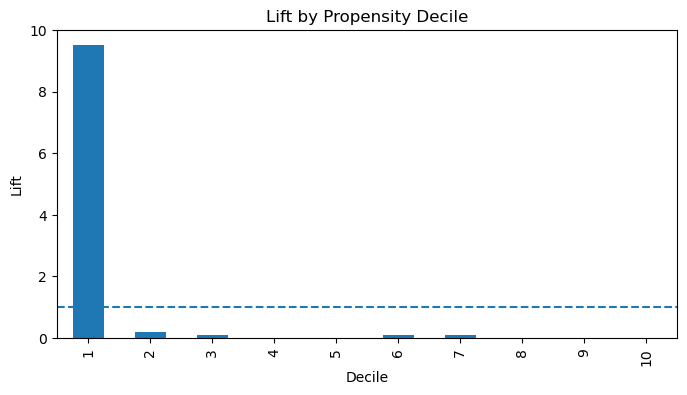

In [26]:
# TODO
decile_table["Lift"].plot(kind="bar",figsize=(8,4))
plt.axhline(1,linestyle="--")
plt.ylabel("Lift")
plt.title("Lift by Propensity Decile")
plt.show()

---
# 8. Lift Chart



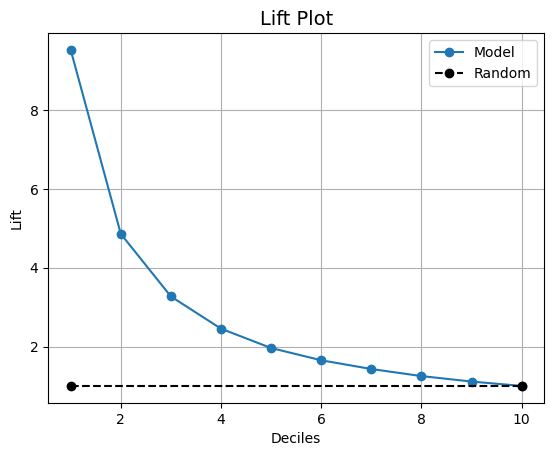

In [27]:
!pip install kds
import kds

# Lift Chart
kds.metrics.plot_lift(y_test, rf.predict_proba(X_test)[:,1])

---
# 9. Business Application — Direct Mail

Now switch from fraud detection to a setting where propensity modeling is especially natural: **direct marketing**.

The goal is not necessarily to label every customer "respond / not respond."

Instead:

> Rank customers by their probability of responding and spend the marketing budget on the most promising customers.

In [ ]:
mail=pd.read_csv("https://raw.githubusercontent.com/martinwg/ISA591/refs/heads/main/data/direct_mail_marketing.csv")
print(mail.shape)
mail.head()

In [ ]:
## map to 1 for "yes"
## yes is the class of interest
mail['deposit'] = mail['deposit'].map({'yes': 1, 'no': 0})

In [ ]:
## get dummies
mail = pd.get_dummies(mail, drop_first=True)

In [ ]:
## create X and y
X = mail.drop('deposit', axis=1)
y = mail['deposit']

In [ ]:
## split 80% and 30% seed = 591
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=591)

In [ ]:
## LOGISTIC REGRESSION
from sklearn.linear_model import LogisticRegression

## instance
lr = LogisticRegression(solver = "liblinear")

## fit
lr.fit(X_train, y_train)

In [ ]:
## predictions
## 0.5
y_pred = lr.predict(X_test)

In [ ]:
## propensities
p_hat = lr.predict_proba(X_test)[:,1]

In [ ]:
df_test = X_test.copy()
df_test['y_true'] = y_test
df_test['p_hat'] = p_hat
df_test.sort_values('p_hat', ascending=False, inplace=True)
df_test.head(50)

In [ ]:
## Calculate LIFT for the top 10 observations (highest propensities)

## overall proportion of 1s
y_test.value_counts() / len(y_test)

## CALCULATE THE LIFT FOR 10 OBS
## SEND THE OFFER TO TOP 10 PROBS
## HOW BETTER THAN RANDOM IS THE MODEL
overall_prop_1s = 0.471484
sample_prop_1s = 9/10

## Practice 9A — Think Before Modeling

Suppose mailing an offer costs money and the firm can contact only 20% of customers.

Which evaluation tools are most directly useful?

- Accuracy?
- Recall?
- AUC?
- Lift?
- Top-$k$ response rate?

Explain.

**Your response:**  
-

---
# 10. Final Challenge

A bank has 100,000 customers but can send a promotional offer to only 10,000.

Model A and Model B have similar accuracy.

Model A has stronger lift in the top decile.

Answer:

1. Why might Model A be more valuable?
2. What does top-decile lift tell the bank?
3. Why might a 0.50 threshold be irrelevant to this decision?
4. What additional business information would you want before choosing the final targeting rule?

**Your response:**  
1.  
2.  
3.  
4.

## Exit Ticket

Complete:

> Classification asks **which class?**, while propensity modeling often asks **who should we prioritize first?**

Why is that distinction important in business analytics?

**Your response:**  
-